# A2 Challenge Analysis: Selecting and Replaying a Command Policy

The Lab established how the released model behaves under argmax. The Challenge begins with an
application requirement. You will select an accept threshold, replay overlapping prediction
traces, and transfer the same policy into firmware.

## Notebook environment

Google Colab is the supported environment for the A2 notebooks. If this notebook is running in
Colab, the setup cell asks for the complete A2 starter ZIP, extracts it into the runtime, changes
the working directory to `Python/`, and verifies the companion files. Upload the complete ZIP when
prompted; do not upload the notebook by itself.

Local Jupyter remains usable when the notebook starts from the package's `Python/` directory.

After completing the notebook in Colab, download the executed `.ipynb` and the generated figures,
then place them in the matching locations in your local A2 package before creating the final
Canvas ZIP.

In [1]:
import io
import os
import sys
import zipfile
from pathlib import Path, PurePosixPath

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    from google.colab import files

    package_root = Path('/content/ECE116_A2')
    python_root = package_root / 'Python'
    if not python_root.is_dir():
        print('Upload the complete ECE116 A2 starter ZIP.')
        uploaded = files.upload()
        archive_names = [name for name in uploaded if name.lower().endswith('.zip')]
        if len(archive_names) != 1:
            raise RuntimeError('Upload exactly one complete A2 starter ZIP.')

        archive_name = archive_names[0]
        with zipfile.ZipFile(io.BytesIO(uploaded[archive_name])) as archive:
            for member_name in archive.namelist():
                member_path = PurePosixPath(member_name)
                if member_path.is_absolute() or '..' in member_path.parts:
                    raise RuntimeError(f'Unsafe archive member: {member_name}')
            archive.extractall(package_root)

    if not python_root.is_dir():
        raise RuntimeError('The uploaded ZIP does not contain Python/ at its root.')
    os.chdir(python_root)
else:
    if Path.cwd().name != 'Python':
        raise RuntimeError(
            'Start the notebook from the A2 package Python/ directory, or use Google Colab.'
        )

Path('../Documentation/Fig').mkdir(parents=True, exist_ok=True)
required_files = ['eval_lib.py', 'keyword_eval.csv', 'score_traces.csv', 'trace_manifest.csv', 'check_command_policy.py']
missing_files = [name for name in required_files if not Path(name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Missing companion files: {missing_files}')

print('environment:', 'Google Colab' if IN_COLAB else 'Local Jupyter')
print('working directory:', Path.cwd())
print('companion files: PASS')

environment: Local Jupyter
working directory: /home/user/ECE116_A2/Python
companion files: PASS


T=0.00  precision=0.849  recall=0.852  false_accepts=71
T=0.05  precision=0.849  recall=0.852  false_accepts=71
T=0.10  precision=0.849  recall=0.852  false_accepts=71
T=0.15  precision=0.849  recall=0.852  false_accepts=71
T=0.20  precision=0.849  recall=0.852  false_accepts=71
T=0.25  precision=0.849  recall=0.852  false_accepts=71
T=0.30  precision=0.850  recall=0.852  false_accepts=70
T=0.35  precision=0.852  recall=0.852  false_accepts=69
T=0.40  precision=0.853  recall=0.848  false_accepts=68
T=0.45  precision=0.867  recall=0.839  false_accepts=60
T=0.50  precision=0.877  recall=0.827  false_accepts=54
T=0.55  precision=0.884  recall=0.801  false_accepts=49
T=0.60  precision=0.899  recall=0.784  false_accepts=41
T=0.65  precision=0.906  recall=0.767  false_accepts=37
T=0.70  precision=0.918  recall=0.741  false_accepts=31
T=0.75  precision=0.930  recall=0.709  false_accepts=25
T=0.80  precision=0.943  recall=0.675  false_accepts=19
T=0.85  precision=0.951  recall=0.623  false_acc

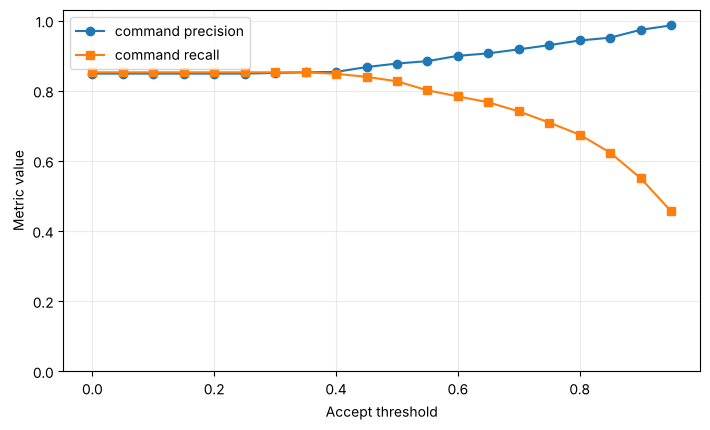

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import eval_lib as ev

DATA = Path('.')
truth, scores, metadata = ev.load_evaluation(DATA / 'keyword_eval.csv')
sweep = ev.threshold_sweep(truth, scores)
for row in sweep:
    print(f"T={row['threshold']:.2f}  precision={row['precision']:.3f}  "
          f"recall={row['recall']:.3f}  false_accepts={row['false_accepts']}")

thresholds = [row['threshold'] for row in sweep]
precision = [row['precision'] for row in sweep]
recall = [row['recall'] for row in sweep]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.plot(thresholds, precision, marker='o', label='command precision')
ax.plot(thresholds, recall, marker='s', label='command recall')
ax.set(xlabel='Accept threshold', ylabel='Metric value', ylim=(0, 1.03))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig('../Documentation/Fig/a2_threshold_sweep.png', dpi=180)
plt.show()

## 1. Apply the supplied operating requirement

The timer policy must meet this requirement on the provided benchmark:

> Among windows accepted as `GO`, `UP`, or `STOP`, at least 97% must have the correct target label.

This is an application requirement, not a value you are expected to invent. A false accepted
command can add time, start the countdown, or stop the timer without the user's intent. The
variable `MINIMUM_PRECISION` records the requirement as `0.97`.

Use the threshold sweep to find the **lowest tested threshold** that meets the requirement. This
selection keeps as many correct commands as possible among the tested operating points while
satisfying the required precision.

In [3]:
MINIMUM_PRECISION = 0.97  # Supplied application requirement. Do not change this value.
choice = ev.lowest_threshold_meeting(sweep, MINIMUM_PRECISION)
assert choice is not None, 'No tested threshold meets the supplied precision requirement.'
ACCEPT_THRESHOLD = round(choice['threshold'], 2)  # C1a: lowest tested threshold meeting the requirement.
print('choice:', choice)
print(f'ACCEPT_THRESHOLD: {ACCEPT_THRESHOLD:.2f}')

choice: {'threshold': 0.8999999999999999, 'accepts': 264, 'correct_accepts': 257, 'false_accepts': 7, 'precision': 0.9734848484848485, 'recall': 0.550321199143469}
ACCEPT_THRESHOLD: 0.90


**Selected operating point:** the lowest tested threshold meeting the 97% requirement is
`ACCEPT_THRESHOLD = 0.90`. At this threshold the benchmark accepts 264 windows as commands, 257 of
them correct, for a command precision of 0.973 and a command recall of 0.550. The 7 false accepts
are the cost the requirement allows: each one would add 10 seconds, start the countdown, or clear
the timer without the user's intent.

The next lower tested threshold, 0.85, reaches only 0.951 precision, so it fails the requirement.
A higher tested threshold, 0.95, raises precision to 0.986 but drops recall to 0.456. That means
more real commands are rejected and the user has to repeat them. A rejected command only costs a
repeat, while a false accepted command changes timer state. The requirement fixes how much false
acceptance is tolerable, and choosing the lowest threshold that meets it keeps as many correct
commands as possible.

## 2. Sequential predictions become events

The model emits overlapping predictions. A word can remain strong across several windows, but one
utterance should produce one command event. Replay the firmware rule: after firing, remain latched
for at least one complete model-window duration. Normally rearm when that time has elapsed and all
three target-command scores are below the release threshold. If scores never release, rearm after
the maximum latch time as a bounded fail-safe. A rearming window emits no event. A later high
window can be accepted after timeout, which trades possible repetition under a stuck score for
recovery from permanent lockout.

The release threshold, minimum latch time, and maximum latch time are supplied policy values. The
replay includes one class-shift edge case and one stuck-score timeout edge case. Keep all three
supplied values unchanged unless you can support a replacement with additional trace evidence.

In [4]:
traces = ev.load_traces(DATA / 'score_traces.csv')
trace_manifest = ev.load_trace_manifest(DATA / 'trace_manifest.csv')
RELEASE_THRESHOLD = 0.55
MINIMUM_LATCH_MS = 1000
MAXIMUM_LATCH_MS = 1500
REPLAY_THRESHOLD = ACCEPT_THRESHOLD
replay = ev.replay_report(
    traces,
    trace_manifest,
    REPLAY_THRESHOLD,
    RELEASE_THRESHOLD,
    MINIMUM_LATCH_MS,
    MAXIMUM_LATCH_MS,
)
for row in replay:
    print(row)
assert all(row['pass'] for row in replay)

{'trace_id': 'single_go', 'expected': '1 x go', 'observed': 'go', 'event_count': 1, 'pass': True}
{'trace_id': 'single_up', 'expected': '1 x up', 'observed': 'up', 'event_count': 1, 'pass': True}
{'trace_id': 'single_stop', 'expected': '1 x stop', 'observed': 'stop', 'event_count': 1, 'pass': True}
{'trace_id': 'unknown_word', 'expected': '0 x none', 'observed': 'none', 'event_count': 0, 'pass': True}
{'trace_id': 'two_go', 'expected': '2 x go', 'observed': 'go, go', 'event_count': 2, 'pass': True}
{'trace_id': 'class_shift_one_utterance', 'expected': '1 x go', 'observed': 'go', 'event_count': 1, 'pass': True}
{'trace_id': 'maximum_latch_recovery', 'expected': '2 x go', 'observed': 'go, go', 'event_count': 2, 'pass': True}


## 3. Inspect every policy decision

A summary can confirm the final event count, but it cannot explain a failure. The next cell prints
the state before and after every window, the strongest class, both rearm conditions, the emitted
event, and the reason for the decision. Predict the trace on paper before running the cell, then
compare each row with your prediction.

The policy contract is:

| State | Condition | New state | Event |
|---|---|---|---|
| Armed | Accepted target | Latched | Matching command |
| Armed | Otherwise | Armed | `none` |
| Latched | Normal release | Armed | `none` |
| Latched | Maximum timeout | Armed | `none` |
| Latched | Otherwise | Latched | `none` |

In [5]:
def show_trace(trace_id, rows):
    timeline = ev.trace_policy(
        rows,
        REPLAY_THRESHOLD,
        RELEASE_THRESHOLD,
        MINIMUM_LATCH_MS,
        MAXIMUM_LATCH_MS,
    )
    print(f'\nTRACE {trace_id}')
    print('time  before   top(score)      release timeout event  after    reason')
    for row in timeline:
        print(
            f"{row['time_ms']:>4}  {row['state_before']:<8} "
            f"{row['top_label']:<7}({row['top_score']:.2f})  "
            f"{str(row['normal_release']):<7} "
            f"{str(row['maximum_timeout']):<7} "
            f"{row['event']:<6} {row['state_after']:<8} {row['reason']}"
        )
    return [row['event'] for row in timeline if row['event'] != 'none']

show_trace('class_shift_one_utterance', traces['class_shift_one_utterance'])
show_trace('maximum_latch_recovery', traces['maximum_latch_recovery'])


TRACE class_shift_one_utterance
time  before   top(score)      release timeout event  after    reason
   0  ARMED    go     (0.95)  False   False   go     LATCHED  accepted target
 250  LATCHED  up     (0.74)  False   False   none   LATCHED  suppressed while latched
 500  LATCHED  stop   (0.92)  False   False   none   LATCHED  suppressed while latched
 750  LATCHED  up     (0.90)  False   False   none   LATCHED  suppressed while latched
1000  LATCHED  unknown(0.70)  True    False   none   ARMED    normal release

TRACE maximum_latch_recovery
time  before   top(score)      release timeout event  after    reason
   0  ARMED    go     (0.95)  False   False   go     LATCHED  accepted target
 250  LATCHED  go     (0.95)  False   False   none   LATCHED  suppressed while latched
 500  LATCHED  go     (0.95)  False   False   none   LATCHED  suppressed while latched
 750  LATCHED  go     (0.95)  False   False   none   LATCHED  suppressed while latched
1000  LATCHED  go     (0.95)  False   Fals

['go', 'go']

## 4. Design two policy tests

Create two traces using `ev.make_trace_window(time_ms, go, up, stop, unknown)`.

1. `student_normal_release` must accept one command, suppress an adjacent high window, rearm by
   normal release, emit nothing from the release window, and accept a later different command.
2. `student_maximum_latch` must remain latched immediately before `1500 ms`, rearm at `1500 ms`
   while a target score remains high, emit nothing from the timeout window, and accept a later
   command.

Choose the timestamps and scores. Record the expected event sequence before running the traces.
The supplied runner exposes every intermediate decision, so revise a test only when you can
explain why its rows did not create the condition you intended.

In [6]:
student_normal_release = [
    # C2a: accept UP, suppress its adjacent windows, hold through an early quiet window and a
    # late high window, rearm by normal release, then accept a different command.
    ev.make_trace_window(0, 0.02, 0.93, 0.02, 0.03),     # ARMED: UP accepted, latch starts at 0 ms.
    ev.make_trace_window(250, 0.01, 0.96, 0.01, 0.02),   # Same utterance, still high: suppressed.
    ev.make_trace_window(500, 0.05, 0.08, 0.05, 0.82),   # Quiet, but only 500 ms elapsed: stays latched.
    ev.make_trace_window(750, 0.03, 0.04, 0.91, 0.02),   # Class shift to STOP while latched: suppressed.
    ev.make_trace_window(1000, 0.03, 0.05, 0.62, 0.30),  # 1000 ms elapsed, STOP still >= 0.55: stays latched.
    ev.make_trace_window(1250, 0.04, 0.05, 0.06, 0.85),  # Every target < 0.55 after 1250 ms: normal release, no event.
    ev.make_trace_window(1500, 0.01, 0.02, 0.95, 0.02),  # ARMED again: later STOP accepted.
]

student_maximum_latch = [
    # C2b: hold GO high through 1499 ms, time out at exactly 1500 ms, then accept a later UP.
    ev.make_trace_window(0, 0.96, 0.01, 0.01, 0.02),     # ARMED: GO accepted, latch starts at 0 ms.
    ev.make_trace_window(250, 0.95, 0.01, 0.01, 0.03),   # Stuck GO: suppressed.
    ev.make_trace_window(500, 0.95, 0.01, 0.01, 0.03),
    ev.make_trace_window(750, 0.94, 0.02, 0.01, 0.03),
    ev.make_trace_window(1000, 0.94, 0.02, 0.01, 0.03),  # Minimum time met, but GO >= 0.55: no normal release.
    ev.make_trace_window(1250, 0.93, 0.02, 0.02, 0.03),
    ev.make_trace_window(1499, 0.93, 0.02, 0.02, 0.03),  # 1 ms before the maximum latch: still latched.
    ev.make_trace_window(1500, 0.93, 0.02, 0.02, 0.03),  # Exactly 1500 ms: timeout rearms, emits nothing.
    ev.make_trace_window(1750, 0.02, 0.95, 0.01, 0.02),  # ARMED again: later UP accepted.
]

student_trace_expectations = {
    'student_normal_release': ['up', 'stop'],  # C2c: expected command events in order.
    'student_maximum_latch': ['go', 'up'],     # C2d: expected command events in order.
}

**C2e: what each trace proves.**

`student_normal_release` shows that one utterance produces one event and that normal release needs
both conditions. UP is accepted at 0 ms (0.93 ≥ 0.90). The adjacent windows are suppressed: UP 0.96
at 250 ms and the class shift to STOP 0.91 at 750 ms. At 500 ms every target score is below 0.55,
but only 500 ms have elapsed, so the policy stays latched. At 1000 ms the minimum time is met, but
STOP is still 0.62, so it stays latched. At 1250 ms both conditions hold, so the policy rearms and
that window emits nothing. STOP 0.95 at 1500 ms is then accepted, giving `['up', 'stop']`.

This trace exposes a policy that rearms on quiet scores alone, without the minimum latch time.
That policy would rearm at 500 ms and accept the STOP 0.91 window at 750 ms, producing an extra
event: `['up', 'stop', 'stop']`. It also exposes a policy with no latch at all, which would fire
again at 250 ms and 750 ms.

`student_maximum_latch` shows that the timeout is a bounded fail-safe at exactly 1500 ms. GO is
accepted at 0 ms and stays between 0.93 and 0.96, so normal release never becomes true. At 1499 ms
the policy is still latched. At 1500 ms the maximum latch is reached, so it rearms with no event,
even though GO is still 0.93. UP 0.95 at 1750 ms is then accepted, giving `['go', 'up']`.

This trace exposes a policy with no maximum-latch timeout. That policy would stay latched forever
under the stuck GO score and miss the UP at 1750 ms (`['go']`). It also exposes a policy that emits
an event from the timeout window, which would fire GO again at 1500 ms (`['go', 'go', 'up']`). The
same happens with a policy that rearms on minimum time alone and ignores the scores: it would rearm
at 1000 ms and accept GO again at 1250 ms.

In [7]:
student_traces = {
    'student_normal_release': student_normal_release,
    'student_maximum_latch': student_maximum_latch,
}

for trace_id, rows in student_traces.items():
    assert rows, f'{trace_id} has no windows. Complete the trace before running this cell.'
    expected = student_trace_expectations[trace_id]
    assert expected, f'{trace_id} has no expected events.'
    observed = show_trace(trace_id, rows)
    print('EXPECTED', expected)
    print('OBSERVED', observed)
    print('MATCH', observed == expected)
    assert observed == expected, f'{trace_id} did not produce its expected events.'


TRACE student_normal_release
time  before   top(score)      release timeout event  after    reason
   0  ARMED    up     (0.93)  False   False   up     LATCHED  accepted target
 250  LATCHED  up     (0.96)  False   False   none   LATCHED  suppressed while latched
 500  LATCHED  unknown(0.82)  False   False   none   LATCHED  suppressed while latched
 750  LATCHED  stop   (0.91)  False   False   none   LATCHED  suppressed while latched
1000  LATCHED  stop   (0.62)  False   False   none   LATCHED  suppressed while latched
1250  LATCHED  unknown(0.85)  True    False   none   ARMED    normal release
1500  ARMED    stop   (0.95)  False   False   stop   LATCHED  accepted target
EXPECTED ['up', 'stop']
OBSERVED ['up', 'stop']
MATCH True

TRACE student_maximum_latch
time  before   top(score)      release timeout event  after    reason
   0  ARMED    go     (0.96)  False   False   go     LATCHED  accepted target
 250  LATCHED  go     (0.95)  False   False   none   LATCHED  suppressed while latc

## 5. Transfer and implement the evaluated policy

Record `ACCEPT_THRESHOLD`, `RELEASE_THRESHOLD`, `MINIMUM_LATCH_MS`, and `MAXIMUM_LATCH_MS` in
`Arduino/Challenge_2/command_policy.cpp`. The notebook, source file, README, and serial evidence
must use the same values and the same release-or-timeout semantics.

Argmax, fixed class-to-event mapping, and model-structure syntax are supplied. Implement the
student-owned temporal decisions in the order listed in the handout. The supplied integration
sketch maps each accepted A2 command event into the unchanged A1 timer interface.

## 6. Check the C++ policy you wrote

Run `python check_command_policy.py` from the package's `Python/` folder. The self-check compiles
your policy against a lightweight model-interface stub and prints named behavior checks. Use its
trace and failure names to diagnose your implementation; do not treat the final pass count as a
substitute for explaining your own two traces.

## 7. Local-condition check

The provided benchmark estimates behavior on held-out corpus speakers. It does not guarantee
performance for your voice, room, distance, or microphone. Run at least five attempts per command
plus ten non-command speech attempts. Report the counts and conditions separately from the
benchmark.